<a href="https://colab.research.google.com/github/ngkhanhly3103/resnet18_fer2013/blob/main/facial_emotion_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import numpy as np
import dlib
from google.colab.patches import cv2_imshow
import time
from google.colab import drive
import bz2
drive.mount('/content/drive')

Mounted at /content/drive


**Detect_face_landmarks**

In [ ]:
file_path = "/content/drive/MyDrive/shape_predictor_68_face_landmarks.dat.bz2"
output_path = "shape_predictor_68_face_landmarks.dat"

with bz2.BZ2File(file_path, "rb") as f_in, open(output_path, "wb") as f_out:
    f_out.write(f_in.read())

# Face Landmark Detector
face_detector = dlib.get_frontal_face_detector()
face_landmark = dlib.shape_predictor("shape_predictor_68_face_landmarks.dat")
# Khoanh vung khuon mat
class FaceDetector:
    def __init__(self):
        # Load Haar Cascade
        self.face_cascade = cv2.CascadeClassifier(
            cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
        )
        self.face_dlib_detector = dlib.get_frontal_face_detector()
        self.face_landmark = dlib.shape_predictor("shape_predictor_68_face_landmarks.dat")

    def face_detector_rect(self,image):

        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        faces_haar = self.face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5)
        faces_dlib = self.face_dlib_detector(gray, 1)

        # Kết hợp kết quả
        all_faces = []
        for (x, y, w, h) in faces_haar:
            all_faces.append(dlib.rectangle(x, y, x+w, y+h))

        for face in faces_dlib:
            all_faces.append(face)

        return all_faces
# Loai bo nhung diem anh khong can thiet
    def select_landmarks(self,image, all_faces):
        landmarks_full = face_landmark(image, all_faces)
        landmarks_selected = []

        for point_id in range(landmarks_full.num_parts):

            if not (0 <= point_id <= 5) and not (11 <= point_id <= 16):
              landmarks_selected.append(
                    (landmarks_full.part(point_id).x, landmarks_full.part(point_id).y)
                )


        return landmarks_selected

# Vẽ các landmarks
    def draw_landmarks(self, image, landmarks_selected):
        for (x, y) in landmarks_selected:
            cv2.circle(image, (x, y), 1, (0, 255, 0), -1)
        return image

**Train model**

In [ ]:
import math
import numpy as np
import pandas as pd

import cv2
!pip install scikit-plot
import seaborn as sns
from matplotlib import pyplot

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report

import tensorflow as tf
from tensorflow.keras import optimizers
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Flatten, Dense, Conv2D, GlobalAveragePooling2D
from tensorflow.keras.layers import Dropout, BatchNormalization, Activation
from tensorflow.keras.callbacks import Callback, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.utils import to_categorical
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torch

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/fer2013.csv')

df.head()

,emotion,pixels,Usage
0,0,70 80 82 72 58 58 60 63 54 58 60 48 89 115 121...,Training
1,0,151 150 147 155 148 133 111 140 170 174 182 15...,Training
2,2,231 212 156 164 174 138 161 173 182 200 106 38...,Training
3,4,24 32 36 30 32 23 19 20 30 41 21 22 32 34 21 1...,Training
4,6,4 0 0 0 0 0 0 0 0 0 0 0 3 15 23 28 48 50 58 84...,Training


In [ ]:
df.emotion.unique()

array([0, 2, 4, 6, 3, 5, 1])

In [ ]:
emotion_label_to_text = {0:'anger', 1:'disgust', 2:'fear', 3:'happiness', 4: 'sadness', 5: 'surprise', 6: 'neutral'}
df.emotion.value_counts()

,count
emotion,
3,8989
6,6198
4,6077
2,5121
0,4953
5,4002
1,547


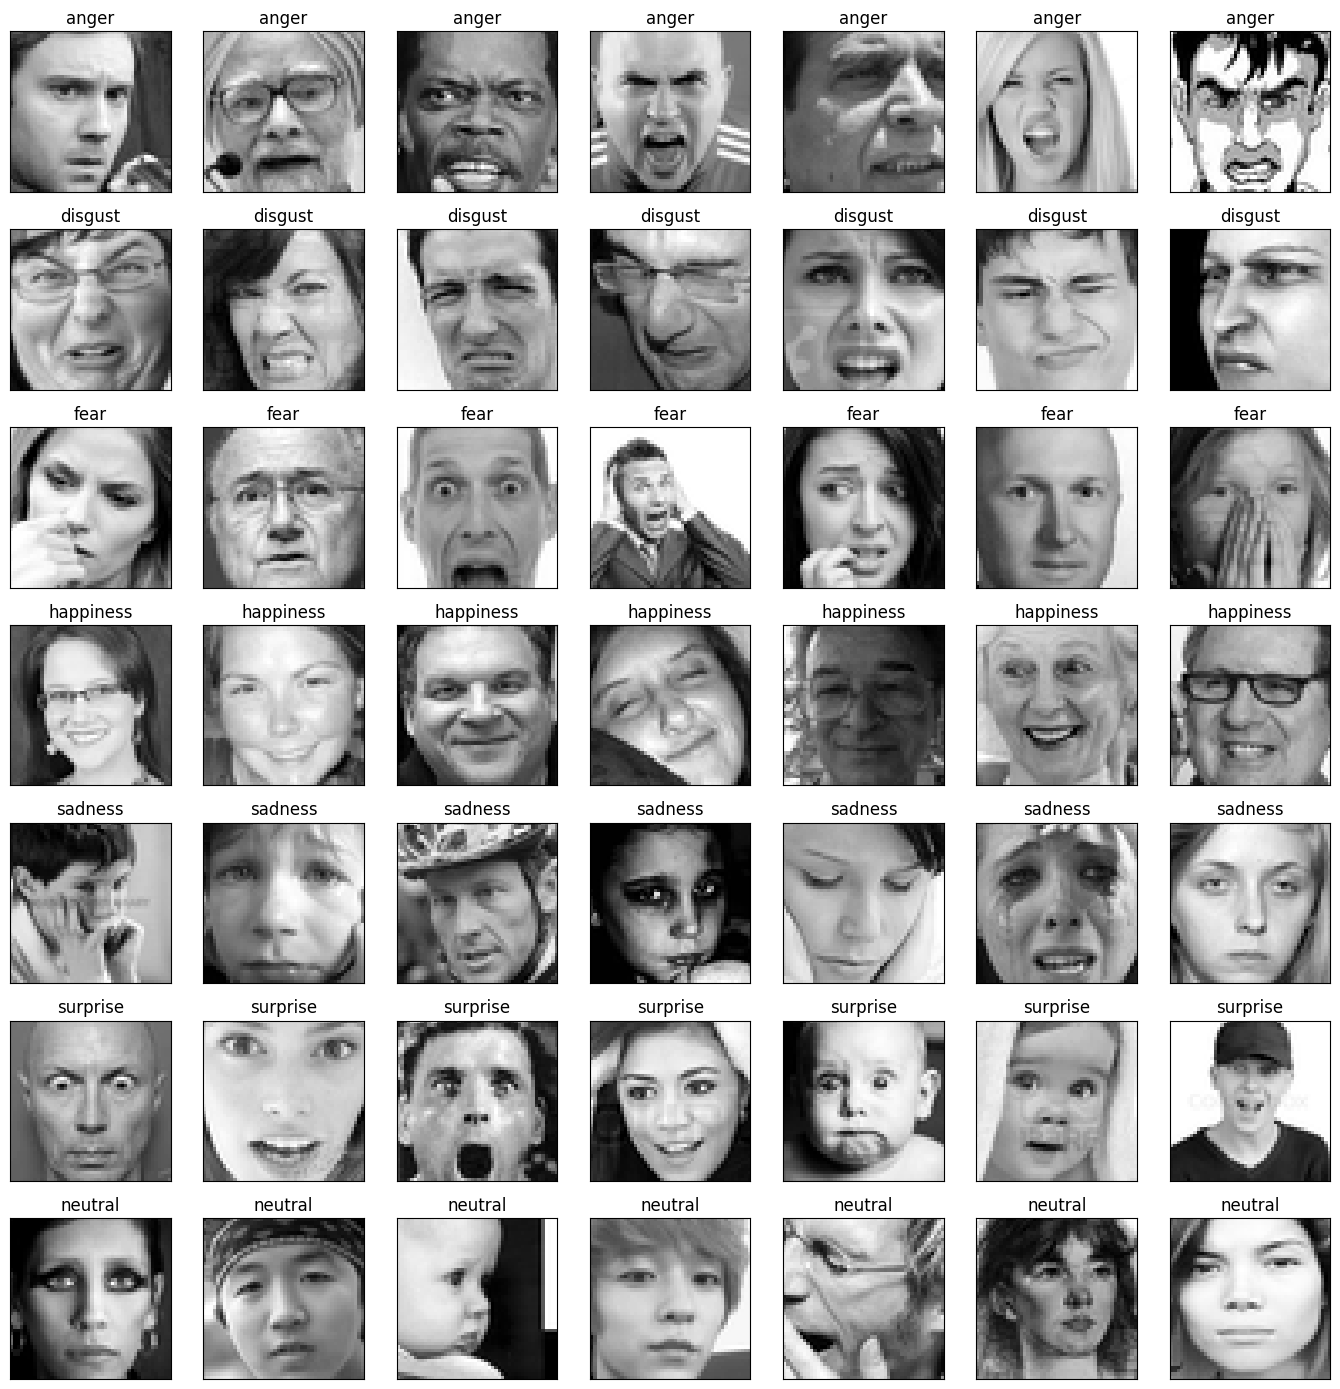

In [ ]:
import matplotlib.pyplot as plt

fig = plt.figure(num=1, figsize=(14, 14))

k = 0
for label in sorted(df.emotion.unique()):
    for j in range(7):
        img_px = df[df.emotion==label].pixels.iloc[j] #lay 7 anh dau tien cua moi cam xuc
        img = np.array(img_px.split(' ')).reshape(48, 48).astype('float32')

        k += 1
        ax = plt.subplot(7, 7, k)
        ax.imshow(img, cmap = 'gray')
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(emotion_label_to_text[label])
        pyplot.tight_layout()

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class FER2013Dataset():
    def __init__(self, df, split='Training', transform=None):
        self.data = df
        self.data = self.data[self.data['Usage'] == split]
        self.transform = transform
        self.images = self.data['pixels'].values
        self.labels = self.data['emotion'].values
        self.face_detector = FaceDetector()

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = np.fromiter(map(int, self.images[idx].split()), dtype=np.uint8)
        img = img.reshape(48, 48)  # ảnh gốc 48x48 grayscale
        img_rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)  # convert thành RGB
        img_bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)

        faces = self.face_detector.face_detector_rect(img_bgr)
        if len(faces) == 0:
            face = img_rgb
        else:
            landmarks = self.face_detector.select_landmarks(img_bgr, faces[0])
            face = self.face_detector.draw_landmarks(img_rgb.copy(), landmarks)


        if self.transform:
            face = self.transform(face)

        label = self.labels[idx]
        return face, label


In [ ]:
BATCH_SIZE = 64
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((48,48)), # Mặc định: interpolation=InterpolationMode.BILINEAR
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

train_dataset = FER2013Dataset(df, split='Training', transform=transform)
val_dataset = FER2013Dataset(df, split='PublicTest', transform=transform)
test_dataset = FER2013Dataset(df, split='PrivateTest', transform=transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

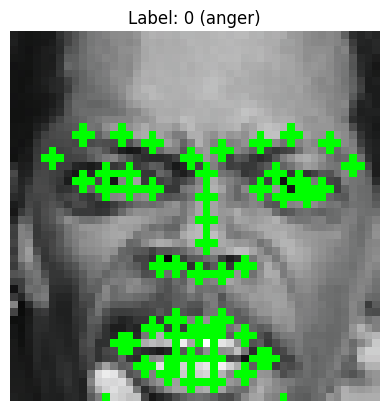

In [ ]:
import matplotlib.pyplot as plt
def show_image(dataset, index):
    image, label = dataset[index]

    # Chuyển tensor -> numpy
    if isinstance(image, torch.Tensor):
        img_np = image.numpy().transpose(1, 2, 0)  # CHW -> HWC
        img_np = img_np * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
        img_np = np.clip(img_np, 0, 1)
    else:
        img_np = image

    plt.imshow(img_np)
    plt.title(f'Label: {label} ({emotion_label_to_text.get(label, "Unknown")})')
    plt.axis('off')
    plt.show()

# Sử dụng
show_image(train_dataset, 10)

In [ ]:
import torch
import torch.nn as nn
import torchvision.models as models

model = models.resnet18(pretrained=True)
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 7)



/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 132MB/s]


In [ ]:
import torch
import torch.nn as nn
from torchvision import models
from torchsummary import summary

num_classes = 7  # Số cảm xúc trong FER2013
model = models.resnet18(pretrained=False)
model.fc = nn.Linear(512, num_classes)
model = model.to(device)  # Với FER2013

summary(model, input_size=(3, 48, 48))

# Kiểm tra đầu ra
x = torch.randn(2, 3, 48, 48).to(device)  # batch 2 ảnh RGB
out = model(x)
print(out.shape)

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 24, 24]           9,408
       BatchNorm2d-2           [-1, 64, 24, 24]             128
              ReLU-3           [-1, 64, 24, 24]               0
         MaxPool2d-4           [-1, 64, 12, 12]               0
            Conv2d-5           [-1, 64, 12, 12]          36,864
       BatchNorm2d-6           [-1, 64, 12, 12]             128
              ReLU-7           [-1, 64, 12, 12]               0
            Conv2d-8           [-1, 64, 12, 12]          36,864
       BatchNorm2d-9           [-1, 64, 12, 12]             128
             ReLU-10           [-1, 64, 12, 12]               0
       BasicBlock-11           [-1, 64, 12, 12]               0
           Conv2d-12           [-1, 64, 12, 12]          36,864
      BatchNorm2d-13           [-1, 64, 12, 12]             128
             ReLU-14           [-1, 64,

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [ ]:
model = model.to(device)
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    running_loss = 0.0  # Khởi tạo running_loss
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()  # Đảm bảo là zero gradient trước khi tính toán

        outputs = model(images)  # Dự đoán từ mô hình
        loss = criterion(outputs, labels)  # Tính loss

        loss.backward()  # Lan truyền ngược
        optimizer.step()  # Cập nhật trọng số

        running_loss += loss.item()  # Cộng dồn loss
        _, predicted = torch.max(outputs.data, 1)  # Tìm nhãn dự đoán
        total += labels.size(0)  # Cộng số lượng ảnh
        correct += (predicted == labels).sum().item()  # Đếm số ảnh đúng

    epoch_loss = running_loss / len(loader)  # Tính trung bình loss
    epoch_acc = 100 * correct / total  # Tính accuracy
    return epoch_loss, epoch_acc


def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0.0  # Khởi tạo tổng loss
    correct = 0

    with torch.no_grad():  # Tắt tính toán gradient
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)  # Dự đoán từ mô hình
            loss = criterion(outputs, labels)  # Tính loss

            total_loss += loss.item() * images.size(0)  # Cộng dồn loss
            _, predicted = torch.max(outputs.data, 1)  # Tìm nhãn dự đoán
            correct += (predicted == labels).sum().item()  # Đếm số ảnh đúng

    avg_loss = total_loss / len(loader.dataset)  # Tính loss trung bình
    acc = 100*correct / len(loader.dataset)  # Tính accuracy
    return avg_loss, acc

In [ ]:
import time

EPOCHS = 50
best_val_acc = 0

history = {
        'train_loss': [],
        'val_loss': [],
        'train_acc': [],
        'val_acc': [],
        'best_weights': None,
        'best_epoch': 0
    }

for epoch in range(EPOCHS):
    start_time = time.time()  # Đo thời gian bắt đầu epoch

    # Huấn luyện một epoch
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)

    # Đánh giá mô hình trên validation set
    val_loss, val_acc = evaluate(model, val_loader, criterion)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_acc': val_acc
        }, 'facial_model_best.pth')
    # Tính thời gian cho một epoch
    epoch_time = time.time() - start_time

    print(f"Epoch {epoch+1}/{EPOCHS} - Time: {epoch_time:.2f}s")
    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
    print(f"Val   Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")
    print("-" * 50)  # In dấu gạch ngang để phân biệt giữa các epoch

Epoch 1/50 - Time: 150.58s
Train Loss: 1.3132, Train Acc: 50.0505
Val   Loss: 1.2172, Val Acc: 53.8312
--------------------------------------------------
Epoch 2/50 - Time: 146.51s
Train Loss: 1.1749, Train Acc: 56.3726
Val   Loss: 1.2530, Val Acc: 53.1903
--------------------------------------------------
Epoch 3/50 - Time: 147.86s
Train Loss: 1.0645, Train Acc: 60.4270
Val   Loss: 1.1889, Val Acc: 56.6732
--------------------------------------------------
Epoch 4/50 - Time: 149.63s
Train Loss: 0.9358, Train Acc: 65.5230
Val   Loss: 1.1628, Val Acc: 56.8125
--------------------------------------------------
Epoch 5/50 - Time: 151.40s
Train Loss: 0.8526, Train Acc: 69.1316
Val   Loss: 1.2877, Val Acc: 55.6144
--------------------------------------------------
Epoch 6/50 - Time: 153.68s
Train Loss: 0.6910, Train Acc: 74.7745
Val   Loss: 1.2577, Val Acc: 57.7320
--------------------------------------------------
Epoch 7/50 - Time: 151.29s
Train Loss: 0.5867, Train Acc: 79.4803
Val   Loss

In [ ]:
torch.save(model.state_dict(), '/content/drive/MyDrive/Colab Notebooks/Đồ án 2/Facial/facial_model_best.pth')

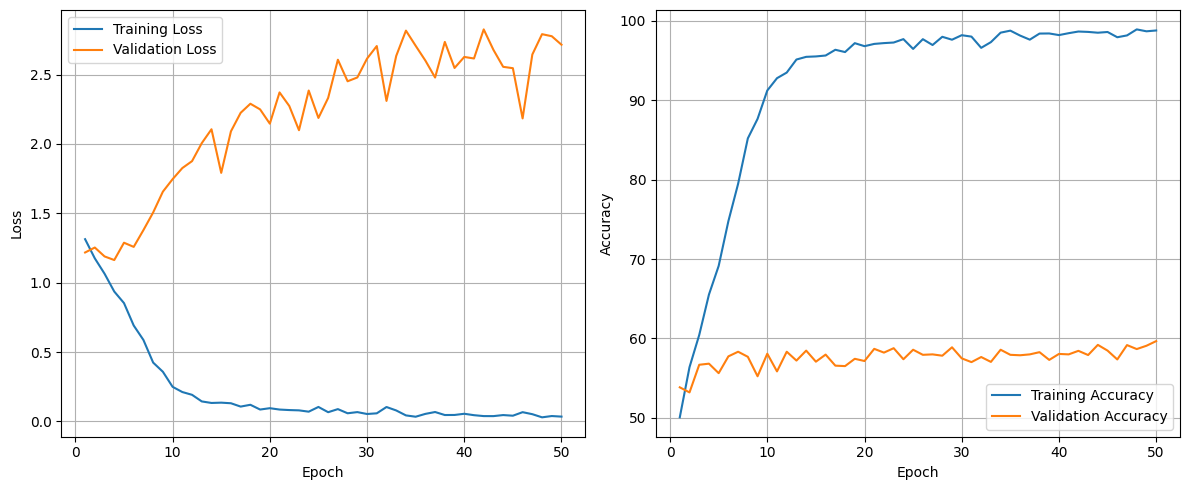

In [ ]:
epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 5))

# Loss plot
plt.subplot(1, 2, 1)
plt.plot(epochs, history['train_loss'], label='Training Loss')
plt.plot(epochs, history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)


# Accuracy plot
plt.subplot(1, 2, 2)
plt.plot(epochs, history['train_acc'], label='Training Accuracy')
plt.plot(epochs, history['val_acc'], label='Validation Accuracy')
plt.xlabel('Epoch',)
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Test Accuracy: 57.8155%
Classification Report:
              precision    recall  f1-score   support

       Angry     0.4253    0.4929    0.4566       491
     Disgust     0.5946    0.4000    0.4783        55
        Fear     0.5082    0.4129    0.4556       528
       Happy     0.7199    0.8305    0.7713       879
         Sad     0.4564    0.4057    0.4296       594
    Surprise     0.7143    0.7452    0.7294       416
     Neutral     0.5398    0.4984    0.5183       626

    accuracy                         0.5782      3589
   macro avg     0.5655    0.5408    0.5484      3589
weighted avg     0.5709    0.5782    0.5718      3589



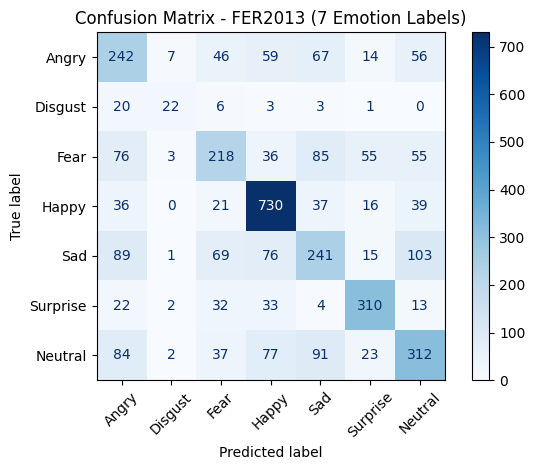

In [ ]:
#Test and Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score
model = models.resnet18(pretrained=True)
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 7)
model.load_state_dict(torch.load('/content/drive/MyDrive/Colab Notebooks/Đồ án 2/Facial/facial_model_best.pth'))
model = model.to(device)
model.eval()
y_true, y_pred = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())

# Tính độ chính xác
test_acc = accuracy_score(y_true, y_pred)
print(f"Test Accuracy: {test_acc:.4%}")

# In classification report
labels_name = ['Angry', 'Disgust', 'Fear', 'Happy', 'Sad', 'Surprise', 'Neutral']
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=labels_name, digits=4))

# Vẽ confusion matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels_name)
disp.plot(cmap=plt.cm.Blues, xticks_rotation=45)
plt.title("Confusion Matrix - FER2013 (7 Emotion Labels)")
plt.tight_layout()
plt.show()


Angry: 29.70%
Disgust: 0.36%
Fear: 3.12%
Happy: 0.55%
Sad: 56.61%
Surprise: 0.05%
Neutral: 9.60%


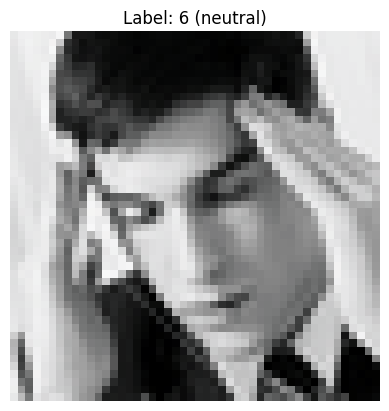

In [ ]:
number = 2

image, label = test_dataset[number]
image = image.unsqueeze(0)  # [1, 3, 48, 48]
labels = ['Angry', 'Disgust', 'Fear', 'Happy', 'Sad', 'Surprise', 'Neutral']
model = models.resnet18(pretrained=True)
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 7)
model.load_state_dict(torch.load('/content/drive/MyDrive/Colab Notebooks/Đồ án 2/Facial/facial_model_best.pth'))

model = model.to(device)
model.eval()
with torch.no_grad():
    image = image.to(device)
    output = model(image)
    probs = torch.softmax(output, dim=1)[0]
    for i, p in enumerate(probs):
        print(f'{labels[i]}: {p.item() * 100:.2f}%')

show_image(test_dataset, number)